# Mushroom Classification — MLME Miniproject
## 1. Introduction and Problem Definition

### 1.1 Objective

The aim of this project is to build a machine learning system that can predict whether a mushroom is edible or poisonous based on its physical characteristics.

I use the Mushroom dataset from the UCI Machine Learning Repository, which contains 8,124 observations with 22 input features describing characteristics such as cap shape, odor, gill color and habitat. The class distribution is relatively balanced with 4,208 edible (51.8%) and 3,916 poisonous (48.2%)
UCI Machine Learning Repository. Mushroom dataset.
https://archive.ics.uci.edu/dataset/73/mushroom

### 1.2 Machine Learning Problem

This is a supervised binary classification problem because the dataset contains labeled examples, and the goal is to predict one of two classes:

0 — Edible

1 — Poisonous

The models are trained using an existing dataset rather than continuously learning from new observations, making this an example of batch learning.

### 1.3 Evaluation Strategy

An important consideration is that predicting a poisonous mushroom as edible is more serious than predicting an edible mushroom as poisonous.

For this reason, I focus especially on recall for the poisonous class, as it measures how many poisonous mushrooms the model correctly identifies.

I also evaluate accuracy, precision, F1-score and confusion matrices to get a more complete understanding of model performance.

### 1.4 Methodology

I follow the general machine learning workflow presented in Chapter 2 of Géron's Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow (3rd edition).

I begin by exploring and preparing the dataset, before comparing three classification algorithms of different complexity: Logistic Regression, Support Vector Machine (SVM) and Random Forest.

I then investigate how hyperparameters, regularization, feature selection and feature engineering affect performance.

The dataset is divided into 80% training data and 20% test data. I use five-fold stratified cross-validation on the training data for model evaluation and hyperparameter tuning, keeping the test set separate until the final evaluation. A fixed random state (67 ) was used to ensure reproducibility.

This follows Géron's approach of using training and validation data for model development before evaluating the selected model on unseen test data. This allows the dataset to be split into the same training and test sets each time the code is executed, making model comparisons more consistent. The value 67 is arbitrary and does not influence the quality of the split.

The purpose is to compare different machine learning approaches and understand how the choices made throughout the process affect classification performance.

An initial inspection of the training data revealed that stalk-root was the only feature containing missing values, with 1,998 missing observations (30.7% of the training set).

## 2. Missing Value Analysis
Several strategies were considered, including removing incomplete observations, dropping the feature, and imputing missing values using the most frequent category.

For this project, missing values will initially be treated as a separate category (missing). This preserves all observations without assuming that unobserved stalk-root characteristics belong to the most frequent category. The transformation will be implemented during preprocessing to avoid data leakage.

## 3. Feature Analysis
All 22 input features are categorical, representing physical characteristics of mushrooms. Since these categories have no inherent numerical order, one-hot encoding was selected to prepare the features for machine learning models.

The stalk-root feature contained 1,998 missing values (30.7% of the training set). These will be represented as a separate category during preprocessing to preserve the observations without assuming their missing characteristics.

The veil-type feature was found to be constant across all 6,499 training observations, containing only the value p. As it provides no variation for distinguishing between classes, it will be excluded during preprocessing.

These decisions were based exclusively on the training data to avoid influencing model development using information from the test set.

## 4. Data Preprocessing
A preprocessing pipeline was constructed using scikit-learn's Pipeline and ColumnTransformer to ensure consistent transformations.

The constant feature veil-type was excluded, leaving 21 categorical input features. Missing values were handled using SimpleImputer, replacing them with a separate category (missing) to preserve observations without assuming their original values.

Since the categorical features have no inherent numerical order, OneHotEncoder was used instead of ordinal encoding. The encoder was configured with handle_unknown="ignore" to accommodate previously unseen categories.

The resulting training data contained 116 numerical features, compared with the original 22 categorical features. The number of observations remained unchanged at 6,499.

For model development and cross-validation, preprocessing will be included within each classifier's pipeline to prevent information leakage between training and validation folds.

In [40]:
%pip install ucimlrepo pandas


I retrieve the dataset directly from UCI and separate the input features (X) from the target labels (y). Keeping them separate makes the later train/test split and model training clearer.

In [41]:

from ucimlrepo import fetch_ucirepo

# Fetch the Mushroom dataset from UCI
mushroom = fetch_ucirepo(id=73)

# Separate input features and target labels
X = mushroom.data.features
y = mushroom.data.targets

# Display the first 5 rows
display(X.head())


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


Initial Dataset Check
Before working with the data, I check its dimensions and the number of edible and poisonous examples. This gives me a basic overview and helps me spot any obvious problems with the import.

In [42]:

# Check the size of our dataset
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Check how many edible and poisonous mushrooms we have
print("\nMushroom classes:")
print(y.value_counts())

Features shape: (8124, 22)
Target shape: (8124, 1)

Mushroom classes:
poisonous
e            4208
p            3916
Name: count, dtype: int64


#Training and Test Split
I reserve 20% of the observations as a test set before detailed exploration. I use stratify=y so both subsets contain approximately the same proportions of edible and poisonous mushrooms. A fixed random state makes the split repeatable. The test set will not be used to choose preprocessing decisions or tune models.

This follows the train/test separation recommended in Géron (2022, Chapter 2).

In [43]:
from sklearn.model_selection import train_test_split

# Split into training (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=67,
    stratify=y
)

print("Training mushrooms:", len(X_train))
print("Test mushrooms:", len(X_test))


Training mushrooms: 6499
Test mushrooms: 1625


#Exploring the Training Data
### Missing Values:
I check for missing values in the training data only, so information from the test set does not influence my preprocessing choices. The stalk-root feature is the only feature with missing values: 1,998 training observations (30.7%).

I considered dropping incomplete rows, dropping the feature, or replacing missing values. I chose to keep the observations and represent missingness as a separate category (missing). This avoids guessing an unknown stalk-root value.

In [44]:

# Count missing values in each feature
missing_values = X_train.isnull().sum()

print(missing_values)


cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  1998
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64


###Inspecting stalk-root
I look at the frequency of each stalk-root category, including missing entries, to better understand how much information is unavailable.

In [45]:

# Examine the distribution of stalk-root values
print(X_train["stalk-root"].value_counts(dropna=False))

stalk-root
b      3013
NaN    1998
e       884
c       447
r       157
Name: count, dtype: int64


##Feature Types
I check the data types because they determine which transformations make sense. These features describe categories rather than continuous numerical measurements, so I will use categorical encoding instead of numerical scaling or skewness transformations.

In [46]:

# Inspect the data types of all features
print(X_train.dtypes)



cap-shape                   object
cap-surface                 object
cap-color                   object
bruises                     object
odor                        object
gill-attachment             object
gill-spacing                object
gill-size                   object
gill-color                  object
stalk-shape                 object
stalk-root                  object
stalk-surface-above-ring    object
stalk-surface-below-ring    object
stalk-color-above-ring      object
stalk-color-below-ring      object
veil-type                   object
veil-color                  object
ring-number                 object
ring-type                   object
spore-print-color           object
population                  object
habitat                     object
dtype: object


###Number of Categories
I count the unique values in each feature to see how many categories need to be encoded. This also helps identify features that contain no variation.

In [47]:

# Count unique categories for each feature
unique_values = X_train.nunique()

print(unique_values)



cap-shape                    6
cap-surface                  4
cap-color                   10
bruises                      2
odor                         9
gill-attachment              2
gill-spacing                 2
gill-size                    2
gill-color                  12
stalk-shape                  2
stalk-root                   4
stalk-surface-above-ring     4
stalk-surface-below-ring     4
stalk-color-above-ring       9
stalk-color-below-ring       9
veil-type                    1
veil-color                   4
ring-number                  3
ring-type                    5
spore-print-color            9
population                   6
habitat                      7
dtype: int64


###Constant Feature: veil-type
The training data shows that veil-type has the same value (p) for all 6,499 observations. Because it cannot distinguish between classes in this training set, I remove it from the model inputs.

In [48]:
# Inspect the constant feature
print(X_train["veil-type"].value_counts(dropna=False))


veil-type
p    6499
Name: count, dtype: int64


#Preparing the Data
##Choose the Input Features
I exclude the constant veil-type column, leaving 21 categorical input features. The original dataset still contains 22 input features; one is simply not used for modeling.

In [49]:
# Select features, excluding the constant veil-type feature
categorical_features = X_train.columns.drop("veil-type")

print("Number of selected features:", len(categorical_features))
print(categorical_features.tolist())


Number of selected features: 21
['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']


###Build the Preprocessing Pipeline
I use SimpleImputer to replace missing entries with the category missing, followed by OneHotEncoder to convert categories into numerical indicator columns. One-hot encoding is appropriate here because categories such as odor or cap shape have no natural numerical order. I set handle_unknown="ignore" so unseen categories do not cause an error when the model receives new data.

I put these steps into a Pipeline and ColumnTransformer so the same transformations can later be fitted inside each cross-validation fold. This is important for avoiding data leakage (Géron, 2022, Chapter 2).

In [50]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Preprocessing for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Apply preprocessing to our selected features
preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created!")


Preprocessing pipeline created!


###Check the Transformed Shape
I inspect the prepared training data to confirm that the number of observations is unchanged and to see how many numerical columns the one-hot encoding creates. This inspection fits a temporary preprocessing object on the training set only; the model pipelines below refit preprocessing separately during cross-validation.

In [51]:

# Fit and transform the training features
X_train_prepared = preprocessor.fit_transform(X_train)

# Check the new dimensions
print("Original shape:", X_train.shape)
print("Prepared shape:", X_train_prepared.shape)


Original shape: (6499, 22)
Prepared shape: (6499, 116)


###Inspect Encoded Features
I display some of the encoded column names and values to make the transformation easier to understand. Each indicator column represents a particular category, rather than a numerical ranking of the original categories.

In [52]:

import pandas as pd

# Get the names of the encoded features
feature_names = preprocessor.get_feature_names_out()

# Convert the prepared data into a readable table
X_train_prepared_df = pd.DataFrame(
    X_train_prepared.toarray()
    if hasattr(X_train_prepared, "toarray")
    else X_train_prepared,
    columns=feature_names,
    index=X_train.index
)

# Display the first five mushrooms and first ten encoded columns
display(X_train_prepared_df.iloc[:5, :10])


,categorical__cap-shape_b,categorical__cap-shape_c,categorical__cap-shape_f,categorical__cap-shape_k,categorical__cap-shape_s,categorical__cap-shape_x,categorical__cap-surface_f,categorical__cap-surface_g,categorical__cap-surface_s,categorical__cap-surface_y
7645,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
5669,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1940,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
5394,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3125,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


###Encode the Target Labels
I convert the class labels into 0 for edible and 1 for poisonous. Defining poisonous as the positive class is important because recall and false negatives will then refer to poisonous mushrooms.

In [53]:

# Convert target labels into binary values
y_train_binary = y_train["poisonous"].map({
    "e": 0,
    "p": 1
})

# Inspect the result
print(y_train_binary.value_counts())


poisonous
0    3366
1    3133
Name: count, dtype: int64


#Logistic Regression
###Create a Baseline Model
I start with Logistic Regression because it is a relatively simple and interpretable classifier. The complete pipeline includes preprocessing, so every training or validation fold receives transformations learned only from its training portion.

In [54]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create a complete pipeline
log_reg_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=67
    ))
])

print("Logistic Regression pipeline created")


Logistic Regression pipeline created


###Fit the Baseline
I first fit the pipeline on the full training set as a basic check that the preprocessing and classifier work together. I will use cross-validation, rather than this training fit, to estimate model performance.

In [55]:

# Train our first classification model
log_reg_pipeline.fit(X_train, y_train_binary)

print("Logistic Regression model trained!")


Logistic Regression model trained!


###Evaluate with Cross-Validation
I use five-fold stratified cross-validation to measure how well Logistic Regression predicts observations left out of each training fold. Stratification keeps class proportions similar across folds. I report accuracy, precision, recall and F1-score instead of relying on accuracy alone.

In [56]:

from sklearn.model_selection import cross_validate, StratifiedKFold

# Create 5 stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=67
)

# Evaluate Logistic Regression
cv_results = cross_validate(
    log_reg_pipeline,
    X_train,
    y_train_binary,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Display average performance
for metric in ["accuracy", "precision", "recall", "f1"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std():.4f})")


accuracy: 0.9997 (+/- 0.0004)
precision: 1.0000 (+/- 0.0000)
recall: 0.9994 (+/- 0.0008)
f1: 0.9997 (+/- 0.0004)


###Baseline Confusion Matrix
A confusion matrix shows the actual numbers of correct and incorrect predictions. I use cross-validated predictions on the training portion to see whether any poisonous mushrooms were incorrectly labeled edible (false negatives).

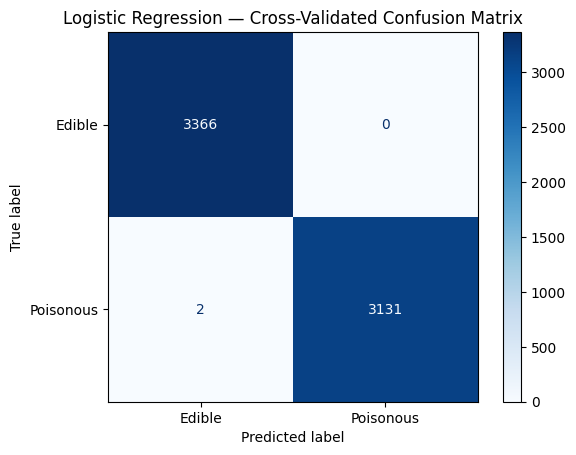

In [57]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate out-of-fold predictions
y_cv_pred = cross_val_predict(
    log_reg_pipeline,
    X_train,
    y_train_binary,
    cv=cv
)

# Calculate the confusion matrix
cm = confusion_matrix(y_train_binary, y_cv_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Edible", "Poisonous"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression — Cross-Validated Confusion Matrix")
plt.show()


#Baseline Logistic Regression — Results

Logistic Regression was evaluated using five-fold stratified cross-validation on the training set. The model achieved a mean accuracy of 99.97%, precision of 100%, recall of 99.94%, and F1-score of 99.97%.

The cross-validated confusion matrix revealed two false negatives and no false positives. Both misclassified observations were poisonous mushrooms predicted as edible.

Although the model achieved very high overall performance, false negatives are particularly important for this classification problem. Therefore, recall for the poisonous class will be prioritized during hyperparameter tuning and model comparison.

The test set was not used during this evaluation.

###Tune Logistic Regression
The parameter C controls the strength of regularization: smaller C means stronger regularization. I compare several values with GridSearchCV, selecting by poisonous-class recall because missing poisonous mushrooms is the error I most want to avoid.

In [58]:

from sklearn.model_selection import GridSearchCV

# Define the hyperparameter values to investigate
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

# Create the grid search
log_reg_grid = GridSearchCV(
    estimator=log_reg_pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1
)

# Run hyperparameter tuning
log_reg_grid.fit(X_train, y_train_binary)

print("Best C:", log_reg_grid.best_params_)
print("Best cross-validation recall:", log_reg_grid.best_score_)


Best C: {'classifier__C': 10}
Best cross-validation recall: 1.0


###Compare Regularization Settings
I inspect the scores for all tested values of C, not just the winning setting. This helps me see whether stronger regularization causes underfitting and whether several settings perform similarly.

In [59]:

import pandas as pd

# Convert grid search results into a DataFrame
grid_results = pd.DataFrame(log_reg_grid.cv_results_)

# Select relevant columns
comparison = grid_results[
    ["param_classifier__C", "mean_test_score", "std_test_score"]
]

# Rename columns for readability
comparison = comparison.rename(columns={
    "param_classifier__C": "C",
    "mean_test_score": "Mean Recall",
    "std_test_score": "Std Recall"
})

display(comparison)


,C,Mean Recall,Std Recall
0,0.01,0.971911,0.005401
1,0.10,0.997128,0.001562
2,1.00,0.999362,0.000782
3,10.00,1.000000,0.000000
4,100.00,1.000000,0.000000


# Hyperparameter Tuning — Logistic Regression Results

The regularization parameter `C` was investigated using `GridSearchCV` with five-fold stratified cross-validation. Five values were evaluated: 0.01, 0.1, 1, 10, and 100.

Mean recall increased from 97.19% at `C=0.01` to 100% at `C=10` and `C=100`. This suggests that stronger regularization restricted the model's ability to identify poisonous mushrooms, while weaker regularization improved recall.

Both `C=10` and `C=100` achieved perfect recall across the validation folds. `GridSearchCV` selected `C=10`, the first of these settings in the parameter grid.

These results demonstrate the effect of regularization on model performance. However, recall alone does not reveal whether improvements were accompanied by additional false positives, so other evaluation metrics must also be considered. This shows that increasing model flexibility helped up to a point, but increasing C further did not improve measured recall.

###Evaluate the Tuned Configuration
I use cross-validated predictions to inspect the tuned model's class-level results and confusion matrix. These are still training-set cross-validation results, not the final independent test evaluation.

In [60]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# Get the selected hyperparameter configuration
best_log_reg = log_reg_grid.best_estimator_

# Generate cross-validated predictions
y_tuned_pred = cross_val_predict(
    best_log_reg,
    X_train,
    y_train_binary,
    cv=cv
)

# Display evaluation metrics
print(classification_report(
    y_train_binary,
    y_tuned_pred,
    target_names=["Edible", "Poisonous"]
))

# Display confusion matrix values
print("Confusion matrix:")
print(confusion_matrix(y_train_binary, y_tuned_pred))


              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00      3366
   Poisonous       1.00      1.00      1.00      3133

    accuracy                           1.00      6499
   macro avg       1.00      1.00      1.00      6499
weighted avg       1.00      1.00      1.00      6499

Confusion matrix:
[[3366    0]
 [   0 3133]]


#Tuned Logistic Regression Evaluation

The selected Logistic Regression configuration (`C=10`) achieved 100% accuracy, precision, recall, and F1-score in cross-validated predictions on the training dataset. The confusion matrix showed no false positives or false negatives, compared with two false negatives for the baseline model (`C=1`).

These results suggest that reducing regularization improved the model's ability to classify the validation observations. However, the hyperparameter was selected using the same cross-validation folds, so the result should not be interpreted as an independent estimate of generalization performance. Final evaluation will be performed on the untouched test set after model selection.

#Support Vector Machine (SVM)
###Create an RBF-Kernel SVM
I next try an SVM with an RBF kernel. Unlike a linear classifier, the RBF kernel can model nonlinear relationships between encoded mushroom characteristics. I keep the same preprocessing approach so the comparison is consistent.

In [61]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

# Create the SVM pipeline
svm_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

print("SVM pipeline created!")


SVM pipeline created!


###Baseline Cross-Validation
I evaluate the baseline SVM with the same five stratified folds and performance metrics used for Logistic Regression.

In [62]:

# Evaluate our SVM using 5-fold cross-validation
svm_cv_results = cross_validate(
    svm_pipeline,
    X_train,
    y_train_binary,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Display the average performance
for metric in ["accuracy", "precision", "recall", "f1"]:
    scores = svm_cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std():.4f})")


accuracy: 1.0000 (+/- 0.0000)
precision: 1.0000 (+/- 0.0000)
recall: 1.0000 (+/- 0.0000)
f1: 1.0000 (+/- 0.0000)


###Tune C and gamma
For an RBF SVM, C controls the penalty for classification errors, while gamma controls how locally each training example influences the decision boundary. I test combinations of both to investigate model flexibility and possible underfitting or overfitting.

In [63]:

from sklearn.model_selection import GridSearchCV

# Define SVM hyperparameters
svm_param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__gamma": [0.01, 0.1, 1]
}

# Create grid search
svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1
)

# Run hyperparameter tuning
svm_grid.fit(X_train, y_train_binary)

print("Best parameters:", svm_grid.best_params_)
print("Best cross-validation recall:", svm_grid.best_score_)


Best parameters: {'classifier__C': 1, 'classifier__gamma': 0.1}
Best cross-validation recall: 1.0


###Inspect the SVM Grid Search
I compare the recall for every tested combination. This is more informative than reporting only the best score, since different settings can produce very different behavior.

In [64]:

import pandas as pd

# Convert SVM grid search results to a DataFrame
svm_results = pd.DataFrame(svm_grid.cv_results_)

# Create a table comparing C and gamma
svm_comparison = svm_results.pivot(
    index="param_classifier__C",
    columns="param_classifier__gamma",
    values="mean_test_score"
)

# Improve table labels
svm_comparison.index.name = "C"
svm_comparison.columns.name = "Gamma"

display(svm_comparison.round(4))


Gamma,0.01,0.10,1.00
C,,,
0.1,0.9719,0.9981,0.0
1.0,0.9978,1.0000,1.0
10.0,1.0000,1.0000,1.0


###Investigate a Poorly Performing Setting
I examine one weak SVM configuration using a confusion matrix. This helps explain why recall can be poor even if a classifier appears to be making consistent predictions.

In [65]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

# Create a copy with the poorly performing parameters
svm_failed = clone(svm_pipeline)

svm_failed.set_params(
    classifier__C=0.1,
    classifier__gamma=1
)

# Generate cross-validated predictions
y_failed_pred = cross_val_predict(
    svm_failed,
    X_train,
    y_train_binary,
    cv=cv
)

# Inspect the confusion matrix
print(confusion_matrix(y_train_binary, y_failed_pred))


[[3366    0]
 [3133    0]]


#SVM — Results and Interpretation

An RBF-kernel Support Vector Machine (SVM) was evaluated using five-fold stratified cross-validation. The baseline model (`C=1`, `gamma="scale"`) achieved 100% accuracy, precision, recall, and F1-score.

A grid search investigated combinations of `C` (0.1, 1, 10) and `gamma` (0.01, 0.1, 1). Several combinations achieved 100% recall, and the grid search selected `C=1` and `gamma=0.1`.

However, the combination `C=0.1` and `gamma=1` resulted in 0% recall. Further investigation using cross-validated predictions revealed that this configuration classified every observation as edible, including all 3,133 poisonous mushrooms.

This demonstrates the importance of hyperparameter selection and the limitations of relying solely on accuracy. It also shows that the effects of regularization and kernel parameters must be considered together.

#Random Forest
###Create the Random Forest Pipeline
Random Forest combines many decision trees, allowing the model to learn combinations of mushroom characteristics. I use the same preprocessing and training data as the other classifiers.

In [66]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=67,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created!")


Random Forest pipeline created!


###Baseline Cross-Validation
I evaluate Random Forest with the same five-fold stratified cross-validation and four metrics. This gives me a comparable baseline before tuning tree complexity.

In [67]:

# Evaluate Random Forest using 5-fold cross-validation
rf_cv_results = cross_validate(
    rf_pipeline,
    X_train,
    y_train_binary,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Display average performance
for metric in ["accuracy", "precision", "recall", "f1"]:
    scores = rf_cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std():.4f})")


accuracy: 1.0000 (+/- 0.0000)
precision: 1.0000 (+/- 0.0000)
recall: 1.0000 (+/- 0.0000)
f1: 1.0000 (+/- 0.0000)


###Tune Tree Complexity
I vary max_depth and min_samples_leaf. Shallow trees are more restricted and may underfit; deeper trees can learn more detailed rules but may also overfit. I select configurations by poisonous-class recall.

In [68]:

from sklearn.model_selection import GridSearchCV

# Define Random Forest hyperparameters
rf_param_grid = {
    "classifier__max_depth": [2, 5, None],
    "classifier__min_samples_leaf": [1, 5]
}

# Create grid search
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1
)

# Run hyperparameter tuning
rf_grid.fit(X_train, y_train_binary)

print("Best parameters:", rf_grid.best_params_)
print("Best cross-validation recall:", rf_grid.best_score_)


Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1}
Best cross-validation recall: 1.0


###Compare the Tree Settings
I inspect the full grid-search table to see how recall changes with tree depth and minimum leaf size. This helps me interpret the effect of complexity rather than just naming the best parameters.

In [69]:

import pandas as pd

# Convert grid search results into a DataFrame
rf_results = pd.DataFrame(rf_grid.cv_results_)

# Select the relevant results
rf_comparison = rf_results[
    [
        "param_classifier__max_depth",
        "param_classifier__min_samples_leaf",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

# Rename columns
rf_comparison.columns = [
    "Max Depth",
    "Min Samples Leaf",
    "Mean Recall",
    "Std Recall"
]

# Display the results
display(rf_comparison)


,Max Depth,Min Samples Leaf,Mean Recall,Std Recall
0,2,1,0.880942,0.013432
1,2,5,0.880942,0.013432
2,5,1,0.978934,0.004207
3,5,5,0.977020,0.003116
4,None,1,1.000000,0.000000
5,None,5,0.999043,0.001276


### Random Forest Classification and Hyperparameter Tuning Results

A Random Forest classifier with 100 decision trees was evaluated using five-fold stratified cross-validation. The baseline model achieved 100% accuracy, precision, recall, and F1-score.

To investigate model complexity, a grid search evaluated maximum tree depths of 2, 5, and unrestricted (`None`), combined with minimum leaf sizes of 1 and 5.

Shallow trees (`max_depth=2`) achieved approximately 88.09% recall, suggesting that their limited complexity prevented them from capturing sufficient classification patterns. Increasing the maximum depth to 5 improved recall to approximately 97.7–97.9%.

The best configuration (`max_depth=None`, `min_samples_leaf=1`) achieved 100% recall. Increasing the minimum leaf size to 5 slightly reduced performance.

These results demonstrate that tree complexity influences classification performance. However, the selected hyperparameters were evaluated through cross-validation on the training data, and final generalization performance remains to be assessed on the untouched test set.

#Feature Selection
###Build a Feature-Selection Pipeline
One-hot encoding produces 116 numerical columns. I investigate whether I can retain good performance with fewer columns using SelectKBest and the chi-squared (chi2) statistic. I keep feature selection inside the pipeline because it uses target labels; selecting features before cross-validation would leak information from validation folds.

In [70]:

from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Pipeline with feature selection
feature_selection_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("feature_selection", SelectKBest(
        score_func=chi2,
        k=30
    )),
    ("classifier", LogisticRegression(
        C=10,
        max_iter=1000,
        random_state=67
    ))
])

print("Feature selection pipeline created!")


Feature selection pipeline created!


###
Compare Different Numbers of Features
I test 10, 30, 60 and all encoded features while keeping the Logistic Regression settings unchanged. This lets me examine the trade-off between a smaller representation and classification performance. Here, “features” means encoded columns, not complete original mushroom attributes

In [71]:

from sklearn.model_selection import cross_validate
from sklearn.base import clone
import pandas as pd

# Numbers of features to investigate
k_values = [10, 30, 60, "all"]

selection_results = []

for k in k_values:
    # Create a fresh pipeline for each experiment
    model = clone(feature_selection_pipeline)
    model.set_params(feature_selection__k=k)

    # Evaluate using the same five folds
    scores = cross_validate(
        model,
        X_train,
        y_train_binary,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"]
    )

    selection_results.append({
        "Features": k,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean()
    })

# Display comparison
selection_comparison = pd.DataFrame(selection_results)
display(selection_comparison.round(4))


,Features,Accuracy,Precision,Recall,F1
0,10,0.9768,0.9758,0.9761,0.9759
1,30,0.9897,0.9929,0.9856,0.9892
2,60,1.0000,1.0000,1.0000,1.0000
3,all,1.0000,1.0000,1.0000,1.0000


#Feature Selection Results

Feature selection was investigated using `SelectKBest` with the chi-squared statistic, applied to the one-hot encoded features. The selection step was included within the model pipeline to prevent data leakage during cross-validation.

Logistic Regression (`C=10`) was evaluated using 10, 30, 60, and all available encoded features.

Using 10 features resulted in 97.61% recall, while 30 features improved recall to 98.56%. Both 60 features and the complete feature set achieved 100% accuracy, precision, recall, and F1-score.

This suggests that I could remove 56 of the 116 encoded columns (48.3%) without reducing the measured cross-validation scores. However, this does not necessarily imply improved generalization or computational efficiency.

The results demonstrate a trade-off between feature reduction and predictive performance, with 60 selected features providing the smallest evaluated representation that maintained perfect cross-validation scores.

#Feature Engineering
###Add Pairwise Interaction Features
I test whether combinations of characteristics help Logistic Regression. I first select 30 encoded columns, then use PolynomialFeatures to add pairwise interactions. This produces 465 columns in total (30 selected columns and 435 interactions). I keep these transformations inside the pipeline to avoid leakage during cross-validation.

In [72]:

from sklearn.preprocessing import PolynomialFeatures
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create a pipeline with interaction features
interaction_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("feature_selection", SelectKBest(
        score_func=chi2,
        k=30
    )),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("classifier", LogisticRegression(
        C=10,
        max_iter=1000,
        random_state=67
    ))
])

print("Interaction feature pipeline created!")


Interaction feature pipeline created!


###Evaluate the Interaction Model
I compare this model with the earlier 30-feature model using the same folds and metrics. The main change is the addition of interaction columns, although this also increases model complexity.

In [73]:

# Evaluate the interaction-feature pipeline
interaction_cv_results = cross_validate(
    interaction_pipeline,
    X_train,
    y_train_binary,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Display the average performance
for metric in ["accuracy", "precision", "recall", "f1"]:
    scores = interaction_cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std():.4f})")


accuracy: 1.0000 (+/- 0.0000)
precision: 1.0000 (+/- 0.0000)
recall: 1.0000 (+/- 0.0000)
f1: 1.0000 (+/- 0.0000)


#Feature Engineering — Interaction Features Results

To investigate feature engineering, pairwise interaction features were generated using `PolynomialFeatures` with `interaction_only=True` and `degree=2`.

The 30 highest-scoring one-hot encoded features were first selected using `SelectKBest`. Pairwise interactions were then generated, producing 465 features in total.

Using Logistic Regression (`C=10`), the interaction-feature model achieved 100% accuracy, precision, recall, and F1-score in five-fold cross-validation. This improved upon the model using only 30 selected features, which achieved 98.56% recall.

These findings suggest that interactions between mushroom characteristics provide useful information for classification. However, generating interactions increased the dimensionality from 30 to 465 features, introducing additional model complexity.

The results demonstrate that feature engineering can improve predictive performance, although its benefits must be considered alongside computational cost and model complexity.

#Model Comparison and Selection
###Compare Candidate Models
I bring the main cross-validation recall results together to compare the different approaches. Several models achieved the same score, so recall alone cannot determine a unique winner. I also consider simplicity, interpretability and the need for additional engineered features.

In [74]:

import pandas as pd

# Compare previously evaluated models
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (baseline)",
        "Logistic Regression (tuned)",
        "SVM (baseline)",
        "Random Forest (baseline)",
        "Logistic Regression + interactions"
    ],
    "Mean CV Recall": [
        cv_results["test_recall"].mean(),
        log_reg_grid.best_score_,
        svm_cv_results["test_recall"].mean(),
        rf_cv_results["test_recall"].mean(),
        interaction_cv_results["test_recall"].mean()
    ]
})

display(model_comparison.round(4))


,Model,Mean CV Recall
0,Logistic Regression (baseline),0.9994
1,Logistic Regression (tuned),1.0000
2,SVM (baseline),1.0000
3,Random Forest (baseline),1.0000
4,Logistic Regression + interactions,1.0000


#Model Comparison and Selection Results

Three classification algorithms were investigated: Logistic Regression, Support Vector Machine (SVM), and Random Forest. All models were evaluated using five-fold stratified cross-validation.

The tuned Logistic Regression model (`C=10`), baseline SVM, and baseline Random Forest achieved 100% recall. Logistic Regression with interaction features also achieved 100% recall.

Since several configurations achieved equivalent performance, model selection was based on additional considerations, including complexity and interpretability.

Tuned Logistic Regression (`C=10`) was selected as the final model because it achieved high classification performance while maintaining a relatively simple and interpretable structure. The interaction-feature model did not provide an additional performance improvement over this configuration.

The selected model will be evaluated on the previously untouched test set to estimate its generalization performance.

#Final Evaluation on the Test Set
###Prepare the Test Labels
After choosing tuned Logistic Regression (C=10), I convert the held-out test labels to the same binary format as the training labels. I do not use the test set to tune or change the model.

In [75]:

# Convert test labels into binary values
y_test_binary = y_test["poisonous"].map({
    "e": 0,
    "p": 1
})

# Check the class distribution
print(y_test_binary.value_counts())


poisonous
0    842
1    783
Name: count, dtype: int64


###Evaluate on Unseen Observations
I use the model selected by GridSearchCV to predict the 1,625 held-out test observations. I calculate accuracy, precision, recall and F1-score, and display the confusion matrix. This is the final independent evaluation; I will not revise the model based on these test results.

Final Test Results:
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000


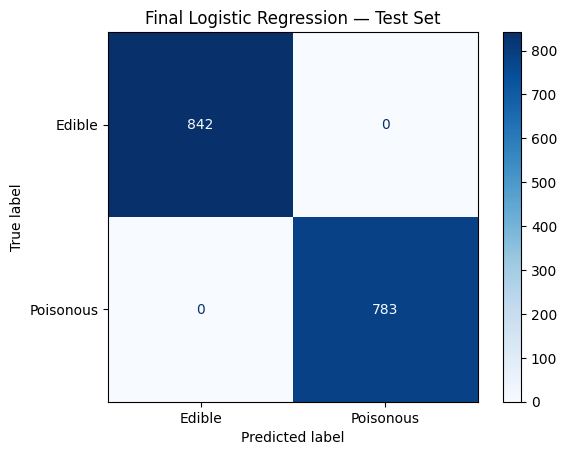

In [76]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Use the selected model trained on the full training set
final_model = log_reg_grid.best_estimator_

# Predict the previously unseen test mushrooms
y_test_pred = final_model.predict(X_test)

# Calculate final test metrics
print("Final Test Results:")
print(f"Accuracy:  {accuracy_score(y_test_binary, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test_binary, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test_binary, y_test_pred):.4f}")
print(f"F1-score:  {f1_score(y_test_binary, y_test_pred):.4f}")

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    y_test_pred,
    display_labels=["Edible", "Poisonous"],
    cmap="Blues"
)

plt.title("Final Logistic Regression — Test Set")
plt.show()


#Final Model Evaluation

The selected Logistic Regression model (`C=10`) was evaluated on the previously reserved test set, containing 1,625 observations (842 edible and 783 poisonous mushrooms).

The model achieved 100% accuracy, precision, recall, and F1-score. The confusion matrix showed no false positives or false negatives, indicating that all test observations were correctly classified.

This is strong performance on unseen observations from the same dataset, but it does not establish perfect performance on new mushroom species or in real-world foraging. I did not use the test results to adjust the model.

The test set was used only after model selection and hyperparameter tuning to provide an independent evaluation of the selected classifier.